# BERT

Using Colab cache for faster access to the 'suicide-watch' dataset.


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Epoch: 17. Loss: 5.6579


100%|██████████| 2176/2176 [06:26<00:00,  5.63it/s]


Epoch: 18. Loss: 4.8023


100%|██████████| 2176/2176 [06:26<00:00,  5.63it/s]


Epoch: 19. Loss: 4.0841


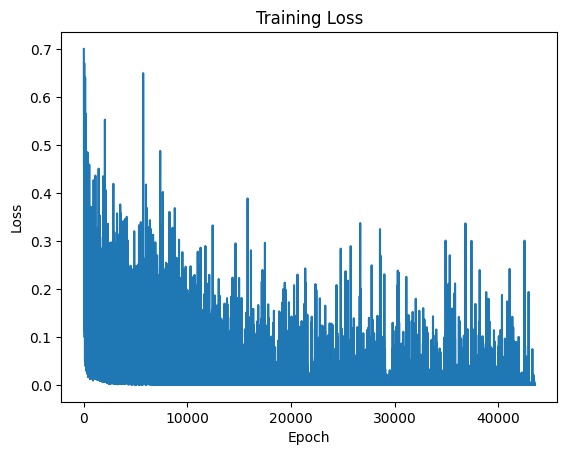

Time: 4.721956846000467
Accuracy: 0.9735
F1: 0.9732728189611699
Precision: 0.9787018255578094
Recall: 0.9679037111334002
ROC-AUC: 0.9948734538610847


In [ ]:
import pandas as pd
import torch
from torch import nn
import numpy as np
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import kagglehub
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dataset_path = kagglehub.dataset_download("nikhileswarkomati/suicide-watch")
data = pd.read_csv(dataset_path + "/Suicide_Detection.csv").sample(frac=0.375, random_state=SEED)
data["label"] = data["class"].astype("category").cat.codes
texts = data["text"].astype(str).tolist()
labels = data["label"].tolist()
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        tokens = tokenizer(
            self.texts[index],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        tokens = {k: v.squeeze(0) for k, v in tokens.items()}
        label_tensor = torch.tensor(self.labels[index], dtype=torch.long)
        return tokens, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0]["input_ids"] for item in batch])
    attention_mask = torch.stack([item[0]["attention_mask"] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return {"input_ids": input_ids, "attention_mask": attention_mask}, labels
dataset = TextDataset(texts, labels)
train_size = int(0.8 * len(dataset))
train_dataset = torch.utils.data.Subset(dataset, range(0, train_size))
eval_dataset   = torch.utils.data.Subset(dataset, range(train_size, train_size + 2000))
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
eval_loader = DataLoader(eval_dataset, batch_size=32,shuffle=False, collate_fn=collate_fn)
class BertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("bert-base-uncased")
        self.classifier = nn.Linear(self.bert.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        embedding = output.last_hidden_state[:, 0]
        logits = self.classifier(embedding)
        return logits
model = BertClassifier().to(device)
param_groups = [
    {"params": model.bert.parameters(), "lr": 5e-6},
    {"params": model.classifier.parameters(), "lr": 3e-4}]
optimizer = optim.AdamW(param_groups)
loss_fn = nn.CrossEntropyLoss()
losses = []
for epoch in range(20):
    model.train()
    total_loss=0
    for batch_inputs, batch_labels in tqdm(train_loader):
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        loss = loss_fn(logits, batch_labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        total_loss+=loss.item()
    print(f"Epoch: {epoch}. Loss: {total_loss:.4f}")
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()
model.eval()
total = 0
correct = 0
preds = []
probs = []
import time
t0 = time.perf_counter()
final_labels = []
with torch.no_grad():
    for batch_inputs, batch_labels in eval_loader:
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_labels.cpu().numpy())
        total += len(batch_labels)
        correct += (predictions == batch_labels).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
print(f"Accuracy: {correct/total:.4f}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

torch.save(model.state_dict(), "bert_suicide_classifier_upgrade.pt")



In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
import kagglehub
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
dataset_path = kagglehub.dataset_download("rvarun11/suicidal-ideation-reddit-dataset")
data = pd.read_csv(dataset_path + "/suicidal_ideation_reddit_annotated.csv")
data["text"] = data["usertext"].astype(str)
texts = data["text"].tolist()
labels = data["label"].astype(int).tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        tokens = tokenizer(
            self.texts[index],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        tokens = {k: v.squeeze(0) for k, v in tokens.items()}
        label_tensor = torch.tensor(self.labels[index], dtype=torch.long)
        return tokens, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0]["input_ids"] for item in batch])
    attention_mask = torch.stack([item[0]["attention_mask"] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return {"input_ids": input_ids, "attention_mask": attention_mask}, labels

dataset = TextDataset(texts, labels)
eval_dataset = dataset
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class BertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("bert-base-uncased")
        self.classifier = nn.Linear(self.bert.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        embedding = output.last_hidden_state[:, 0]
        logits = self.classifier(embedding)
        return logits
model = BertClassifier().to(device)
model.load_state_dict(torch.load("bert_suicide_classifier_upgrade.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
import time
t0 = time.perf_counter()
final_labels = []
with torch.no_grad():
    for batch_inputs, batch_labels in eval_loader:
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_labels.cpu().numpy())
        total += len(batch_labels)
        correct += (predictions == batch_labels).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
print(f"Accuracy: {correct/total:.4f}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 3.79M/3.79M [00:00<00:00, 213MB/s]

Extracting files...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Time: 5.02194311400126
Accuracy: 0.8355
F1: 0.8441496920890573
Precision: 0.8413597733711048
Recall: 0.846958174904943
ROC-AUC: 0.9022672305915195


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import kagglehub
from tqdm import tqdm
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import kagglehub
mapping = {
    "non-suicide": 0,
    "suicide": 1
}
dataset_path = kagglehub.dataset_download("neelakshigupta/suicide-detection")
data = pd.read_csv(dataset_path + "/file1.csv")
data["text"] = data["text"]
data["Suicide"] = data["class"].map(mapping)
data = data.dropna(subset = ["text", "class"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
print(labels[0:20])
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        tokens = tokenizer(
            self.texts[index],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        tokens = {k: v.squeeze(0) for k, v in tokens.items()}
        label_tensor = torch.tensor(self.labels[index], dtype=torch.long)
        return tokens, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0]["input_ids"] for item in batch])
    attention_mask = torch.stack([item[0]["attention_mask"] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return {"input_ids": input_ids, "attention_mask": attention_mask}, labels

dataset = TextDataset(texts, labels)
eval_dataset = dataset
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class BertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("bert-base-uncased")
        self.classifier = nn.Linear(self.bert.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        embedding = output.last_hidden_state[:, 0]
        logits = self.classifier(embedding)
        return logits
model = BertClassifier().to(device)
model.load_state_dict(torch.load("bert_suicide_classifier_upgrade.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
import time
t0 = time.perf_counter()
final_labels = []
with torch.no_grad():
    for batch_inputs, batch_labels in eval_loader:
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_labels.cpu().numpy())
        total += len(batch_labels)
        correct += (predictions == batch_labels).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
print(f"Accuracy: {correct/total:.4f}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 1.45M/1.45M [00:00<00:00, 133MB/s]

Extracting files...
[0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Time: 4.197344087000602
Accuracy: 0.9170
F1: 0.9154786150712831
Precision: 0.9164118246687054
Recall: 0.9145473041709054
ROC-AUC: 0.9697532586917619


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import kagglehub
from tqdm import tqdm
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import kagglehub
mapping = {
    "Not Suicide post": 0,
    "Potential Suicide post ": 1
}
dataset_path = kagglehub.dataset_download("aunanya875/suicidal-tweet-detection-dataset")
data = pd.read_csv(dataset_path + "/Suicide_Ideation_Dataset(Twitter-based).csv")
data["text"] = data["Tweet"]
data["Suicide"] = data["Suicide"].map(mapping)
data = data.dropna(subset=["Tweet", "Suicide"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        tokens = tokenizer(
            self.texts[index],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        tokens = {k: v.squeeze(0) for k, v in tokens.items()}
        label_tensor = torch.tensor(self.labels[index], dtype=torch.long)
        return tokens, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0]["input_ids"] for item in batch])
    attention_mask = torch.stack([item[0]["attention_mask"] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return {"input_ids": input_ids, "attention_mask": attention_mask}, labels

dataset = TextDataset(texts, labels)
eval_dataset = dataset
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class BertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("bert-base-uncased")
        self.classifier = nn.Linear(self.bert.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        embedding = output.last_hidden_state[:, 0]
        logits = self.classifier(embedding)
        return logits
model = BertClassifier().to(device)
model.load_state_dict(torch.load("bert_suicide_classifier_upgrade.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
import time
t0 = time.perf_counter()
final_labels = []
with torch.no_grad():
    for batch_inputs, batch_labels in eval_loader:
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_labels.cpu().numpy())
        total += len(batch_labels)
        correct += (predictions == batch_labels).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
print(f"Accuracy: {correct/total:.4f}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 88.3k/88.3k [00:00<00:00, 63.6MB/s]

Extracting files...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Time: 3.379167294999206
Accuracy: 0.7070
F1: 0.5215004574565416
Precision: 0.6566820276497696
Recall: 0.4324734446130501
ROC-AUC: 0.728182940404348


# DistilBERT

Using Colab cache for faster access to the 'suicide-watch' dataset.


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Epoch: 17. Average Loss: 0.0033


100%|██████████| 2176/2176 [03:55<00:00,  9.25it/s]


Epoch: 18. Average Loss: 0.0031


100%|██████████| 2176/2176 [03:55<00:00,  9.26it/s]


Epoch: 19. Average Loss: 0.0026


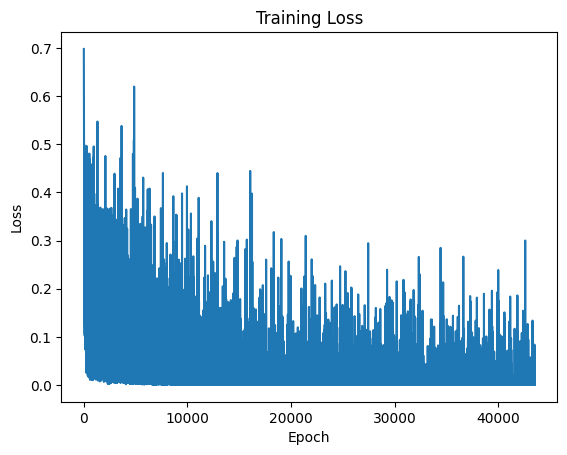

Time: 3.3614711699992768
Accuracy: 0.9700
F1: 0.9694811800610377
Precision: 0.9655521783181358
Recall: 0.9734422880490297
ROC-AUC: 0.9700708012233396


In [ ]:
import pandas as pd
import torch
import numpy as np
from torch import nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import kagglehub
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("nikhileswarkomati/suicide-watch")
data = pd.read_csv(dataset_path + "/Suicide_Detection.csv").sample(frac=0.375, random_state=0)
data["label"] = data["class"].astype("category").cat.codes

texts = data["text"].astype(str).tolist()
labels = data["label"].tolist()

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        tokens = tokenizer(
            self.texts[index],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        tokens = {k: v.squeeze(0) for k, v in tokens.items()}
        label_tensor = torch.tensor(self.labels[index], dtype=torch.long)
        return tokens, label_tensor
def collate_fn(batch):
    input_ids = torch.stack([item[0]["input_ids"] for item in batch])
    attention_mask = torch.stack([item[0]["attention_mask"] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return {"input_ids": input_ids, "attention_mask": attention_mask}, labels
dataset = TextDataset(texts, labels)
train_size = int(0.8 * len(dataset))
train_dataset = torch.utils.data.Subset(dataset, range(0, train_size))
eval_dataset  = torch.utils.data.Subset(dataset, range(train_size, train_size + 2000))
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
eval_loader  = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)
class DistilBertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("distilbert-base-uncased")
        self.classifier = nn.Linear(self.bert.config.hidden_size, 2)
    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        embedding = output.last_hidden_state[:, 0]
        logits = self.classifier(embedding)
        return logits
model = DistilBertClassifier().to(device)
param_groups = [
    {"params": model.bert.parameters(), "lr": 5e-6},
    {"params": model.classifier.parameters(), "lr": 3e-4}]
optimizer = optim.AdamW(param_groups)
loss_fn = nn.CrossEntropyLoss()
losses = []
for epoch in range(20):
    model.train()
    total_loss = 0
    for batch_inputs, batch_labels in tqdm(train_loader):
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        loss = loss_fn(logits, batch_labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        total_loss += loss.item()
    avg_loss = total_loss/len(train_loader)
    print(f"Epoch: {epoch}. Average Loss: {avg_loss:.4f}")
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()
model.eval()
total = 0
correct = 0
preds = []
final_labels = []
import time
t0 = time.perf_counter()
with torch.no_grad():
    for batch_inputs, batch_labels in eval_loader:
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        predictions = logits.argmax(dim=1)
        preds.append(predictions.cpu().numpy())
        final_labels.append(batch_labels.cpu().numpy())
        total += len(batch_labels)
        correct += (predictions == batch_labels).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
print(f"Accuracy: {correct/total:.4f}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, preds)}")

torch.save(model.state_dict(), "distilbert.pt")


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
import kagglehub
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
dataset_path = kagglehub.dataset_download("rvarun11/suicidal-ideation-reddit-dataset")
data = pd.read_csv(dataset_path + "/suicidal_ideation_reddit_annotated.csv")
data["text"] = data["usertext"].astype(str)
texts = data["text"].tolist()
labels = data["label"].astype(int).tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        tokens = tokenizer(
            self.texts[index],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        tokens = {k: v.squeeze(0) for k, v in tokens.items()}
        label_tensor = torch.tensor(self.labels[index], dtype=torch.long)
        return tokens, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0]["input_ids"] for item in batch])
    attention_mask = torch.stack([item[0]["attention_mask"] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return {"input_ids": input_ids, "attention_mask": attention_mask}, labels

dataset = TextDataset(texts, labels)
eval_dataset = dataset
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class DistilBertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("distilbert-base-uncased")
        self.classifier = nn.Linear(self.bert.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        embedding = output.last_hidden_state[:, 0]
        logits = self.classifier(embedding)
        return logits
model = DistilBertClassifier().to(device)
model.load_state_dict(torch.load("distilbert.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
t0 = time.perf_counter()
with torch.no_grad():
    for batch_inputs, batch_labels in eval_loader:
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_labels.cpu().numpy())
        total += len(batch_labels)
        correct += (predictions == batch_labels).sum().item()
t1 = time.perf_counter()
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
print(f"Time: {t1-t0}")
print(f"Accuracy: {correct/total:.4f}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")
print(total)

Using Colab cache for faster access to the 'suicidal-ideation-reddit-dataset' dataset.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Time: 4.122085450999293
Accuracy: 0.8270
F1: 0.8352380952380952
Precision: 0.8368320610687023
Recall: 0.8336501901140685
ROC-AUC: 0.8833485745455714
2000


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import kagglehub
from tqdm import tqdm
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import kagglehub
mapping = {
    "non-suicide": 0,
    "suicide": 1
}
dataset_path = kagglehub.dataset_download("neelakshigupta/suicide-detection")
data = pd.read_csv(dataset_path + "/file1.csv")
data["text"] = data["text"]
data["Suicide"] = data["class"].map(mapping)
data = data.dropna(subset = ["text", "class"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
print(labels[0:20])
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        tokens = tokenizer(
            self.texts[index],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        tokens = {k: v.squeeze(0) for k, v in tokens.items()}
        label_tensor = torch.tensor(self.labels[index], dtype=torch.long)
        return tokens, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0]["input_ids"] for item in batch])
    attention_mask = torch.stack([item[0]["attention_mask"] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return {"input_ids": input_ids, "attention_mask": attention_mask}, labels

dataset = TextDataset(texts, labels)
eval_dataset = dataset
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class DistilBertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("distilbert-base-uncased")
        self.classifier = nn.Linear(self.bert.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        embedding = output.last_hidden_state[:, 0]
        logits = self.classifier(embedding)
        return logits
model = DistilBertClassifier().to(device)
model.load_state_dict(torch.load("distilbert.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
t0 = time.perf_counter()
with torch.no_grad():
    for batch_inputs, batch_labels in eval_loader:
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_labels.cpu().numpy())
        total += len(batch_labels)
        correct += (predictions == batch_labels).sum().item()
t1 = time.perf_counter()
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
print(f"Time: {t1-t0}")
print(f"Accuracy: {correct/total:.4f}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

Using Colab cache for faster access to the 'suicide-detection' dataset.
[0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0]


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Time: 2.8563858319994324
Accuracy: 0.9175
F1: 0.9172102358253889
Precision: 0.904950495049505
Recall: 0.9298067141403866
ROC-AUC: 0.9769633424059554


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import kagglehub
from tqdm import tqdm
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import kagglehub
mapping = {
    "Not Suicide post": 0,
    "Potential Suicide post ": 1
}
dataset_path = kagglehub.dataset_download("aunanya875/suicidal-tweet-detection-dataset")
data = pd.read_csv(dataset_path + "/Suicide_Ideation_Dataset(Twitter-based).csv")
data["text"] = data["Tweet"]
data["Suicide"] = data["Suicide"].map(mapping)
data = data.dropna(subset=["Tweet", "Suicide"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        tokens = tokenizer(
            self.texts[index],
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        tokens = {k: v.squeeze(0) for k, v in tokens.items()}
        label_tensor = torch.tensor(self.labels[index], dtype=torch.long)
        return tokens, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0]["input_ids"] for item in batch])
    attention_mask = torch.stack([item[0]["attention_mask"] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return {"input_ids": input_ids, "attention_mask": attention_mask}, labels

dataset = TextDataset(texts, labels)
eval_dataset = dataset
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class DistilBertClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("distilbert-base-uncased")
        self.classifier = nn.Linear(self.bert.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        embedding = output.last_hidden_state[:, 0]
        logits = self.classifier(embedding)
        return logits
model = DistilBertClassifier().to(device)
model.load_state_dict(torch.load("distilbert.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
t0 = time.perf_counter()
with torch.no_grad():
    for batch_inputs, batch_labels in eval_loader:
        input_ids = batch_inputs["input_ids"].to(device)
        attention_mask = batch_inputs["attention_mask"].to(device)
        batch_labels = batch_labels.to(device)
        logits = model(input_ids, attention_mask)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_labels.cpu().numpy())
        total += len(batch_labels)
        correct += (predictions == batch_labels).sum().item()
t1 = time.perf_counter()
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
print(f"Time: {t1-t0}")
print(f"Accuracy: {correct/total:.4f}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

Using Colab cache for faster access to the 'suicidal-tweet-detection-dataset' dataset.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Time: 2.3063713440005813
Accuracy: 0.6801
F1: 0.4418377321603128
Precision: 0.6208791208791209
Recall: 0.34294385432473445
ROC-AUC: 0.6595748981852584
